# PDF betöltése

Bírói könyv betöltése PyMuPDF-el + alap tulajdonságok check


In [4]:

from pathlib import Path
import pymupdf

PROJECT_ROOT = Path.cwd().resolve().parent
PDF_PATH = PROJECT_ROOT / "data" / "raw" / "wag_code_of_points_2025_2028.pdf"

assert PDF_PATH.exists(), f"PDF not found: {PDF_PATH}"

doc = pymupdf.open(PDF_PATH)

print(f"dokumentum: {PDF_PATH.name}")
print(f"oldalszám: {len(doc)}")


dokumentum: wag_code_of_points_2025_2028.pdf
oldalszám: 210


# Szövegkinyerés oldalanként

Minden oldalról kiveszem a szöveges tartalmat + strukturált formában megpróbálom tárolni, hogy minden oldalhoz rögzítem az oldalszámot az eredeti dokumentumban, a kinyert szöevget, a karakterszámot, szószámot.

`sort=True`-t használom, hogy olvasási sorrendbe rendezzem a doksi elemeket.

In [5]:

pages = []

for page_num, page in enumerate(doc, start=1):
    text = page.get_text("text", sort=True)

    pages.append({
        "page": page_num,
        "text": text,
        "characters": len(text),
        "words": len(text.split())
    })

print(f"kinyert oldalak db: {len(pages)}")
print(f"összes karakter: {sum(p['characters'] for p in pages):,}")
print(f"összes szó: {sum(p['words'] for p in pages):,}")

print("\nElső oldal példa check:\n")
print(pages[0]["text"][:2000])


kinyert oldalak db: 210
összes karakter: 182,578
összes szó: 17,861

Első oldal példa check:

          SzabálykönyvTORNA
           2025-2028

                            Jóváhagyva a FIG Végrehajtó Bizottság által 2024. február
                                      Megjelenés dátuma: 2024. április 22.NŐI
                                                                                            1


# A szövegkinyerés statisztikai vizsgálata
Statisztikával megpróbálom meghatározni, hogy melyik oldalról mennyi szöveget tudtam kiszedni. Ez azért kell, mert sok képes oldal van, például az elemtáblázat, ahol le vannak rajzolva a szaltók és ez vagy 100 oldal az egész szabályzatból, így azt szerteném meghatározni most, hogy melyik odlalakon van pl. annyira kevés szöveg a képek miatt, hogy azt inkább nem érdemes feltölteni.

TELJES DOKUMENTUM STATISZTIKÁJA


,characters,words
count,210.000000,210.000000
mean,869.419048,85.052381
std,1622.654699,145.033578
min,2.000000,1.000000
25%,3.000000,1.000000
50%,3.000000,1.000000
75%,1289.500000,119.750000
max,10246.000000,576.000000


összes oldal: 210
összes karakter: 182,578
összes szó: 17,861


,page,characters,words
0,1,307,16
1,2,2887,236
2,3,4277,258
3,4,10246,282
4,5,9939,340
...,...,...,...
205,206,76,9
206,207,3,1
207,208,3,1
208,209,3,1


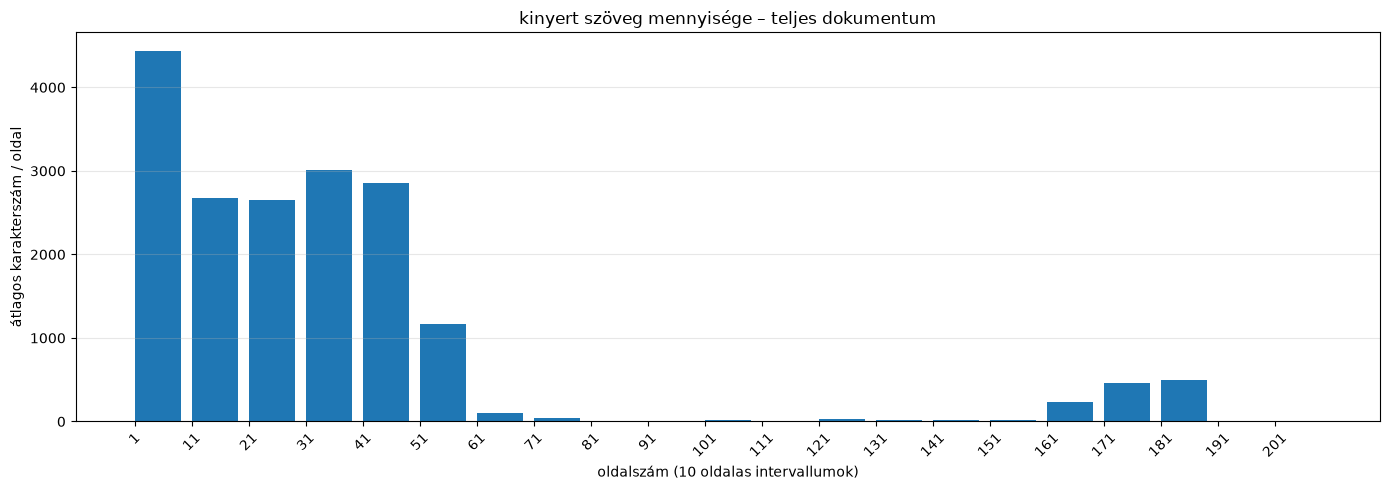

SZÖVEGES OLDALAK STATISZTIKÁJA


,characters,words
count,60.000000,60.000000
mean,2941.233333,289.850000
std,1773.867128,121.236962
min,24.000000,3.000000
25%,2147.500000,207.750000
50%,2813.500000,313.500000
75%,3395.000000,366.500000
max,10246.000000,576.000000


összes oldal: 210
kizárt oldalak: 150
felhasználható oldalak: 60
összes karakter: 176,474
összes szó: 17,391


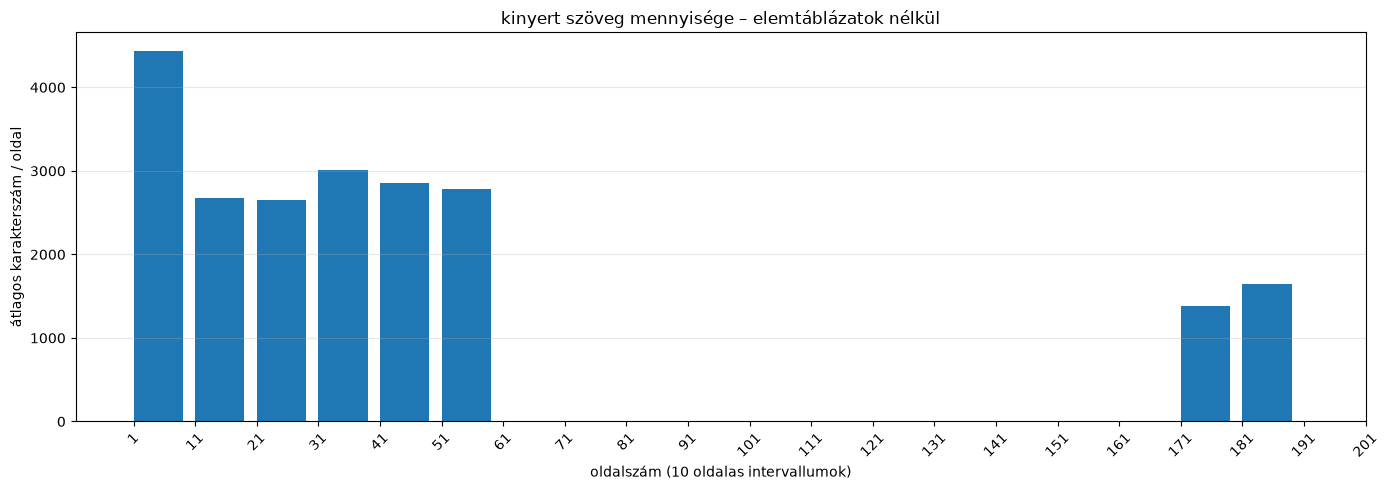

In [13]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#oldalankénti statisztikák
df_pages = pd.DataFrame([
    {
        "page": p["page"],
        "characters": p["characters"],
        "words": p["words"]
    }
    for p in pages
])

print("TELJES DOKUMENTUM STATISZTIKÁJA")
display(df_pages[["characters", "words"]].describe())

print(f"összes oldal: {len(df_pages)}")
print(f"összes karakter: {df_pages['characters'].sum():,}")
print(f"összes szó: {df_pages['words'].sum():,}")

#oldalankénti részletes eredmények
display(df_pages)

#10 oldalas intervallumok
df_pages["page_group"] = ((df_pages["page"] - 1) // 10) * 10 + 1

#átlagos karakterszám intervallumonként
char_stats = df_pages.groupby("page_group")["characters"].mean()

#oszlopdiagram
plt.figure(figsize=(14, 5))

plt.bar(
    char_stats.index,
    char_stats.values,
    width=8,
    align="edge"
)

plt.xticks(
    np.arange(1, 211, 10),
    rotation=45
)

plt.xlabel("oldalszám (10 oldalas intervallumok)")
plt.ylabel("átlagos karakterszám / oldal")
plt.title("kinyert szöveg mennyisége – teljes dokumentum")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


#képalapú elemtáblázatok oldaltartományai  - dokumentumban ellenőrizve
excluded_ranges = [
    (55, 177),
    (184, 210)
]

#kizárandó oldalak megjelölése
excluded_mask = pd.Series(False, index=df_pages.index)

for start, end in excluded_ranges:
    excluded_mask |= df_pages["page"].between(start, end)

#megmaradó, szöveges oldalak
df_text_pages = df_pages.loc[~excluded_mask].copy()

print("SZÖVEGES OLDALAK STATISZTIKÁJA")
display(df_text_pages[["characters", "words"]].describe())

print(f"összes oldal: {len(df_pages)}")
print(f"kizárt oldalak: {excluded_mask.sum()}")
print(f"felhasználható oldalak: {len(df_text_pages)}")
print(f"összes karakter: {df_text_pages['characters'].sum():,}")
print(f"összes szó: {df_text_pages['words'].sum():,}")

#átlagos karakterszám a megmaradó oldalakon
char_stats_filtered = (
    df_text_pages.groupby("page_group")["characters"].mean()
)

#oszlopdiagram
plt.figure(figsize=(14, 5))

plt.bar(
    char_stats_filtered.index,
    char_stats_filtered.values,
    width=8,
    align="edge"
)

plt.xticks(
    np.arange(1, 211, 10),
    rotation=45
)

plt.xlabel("oldalszám (10 oldalas intervallumok)")
plt.ylabel("átlagos karakterszám / oldal")
plt.title("kinyert szöveg mennyisége – elemtáblázatok nélkül")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()




# A kinyert szöveg minőségének ellenőrzése

Megnézem kiválasztott oldalakon hogy milyen a szövegkinyerés -> példa oldalak:
- csak szöveget tartalmazó oldal: 10
- egy táblázatot tartalmazó oldal: 11
- teljes táblázatos oldal: 33
- elemjelölő rajzokat tartalmazó oldal: 25
- képet tartalmazó oldal: 24
- táblázatot és képet tartalmazó oldal: 27
- elemtáblázat oldalak, amik a startisztikában kijöttek, hogy nagyon kevés szöveg van rajtuk: 58


OLDAL: 10 | Csak szöveg
Kinyert karakterek: 3246


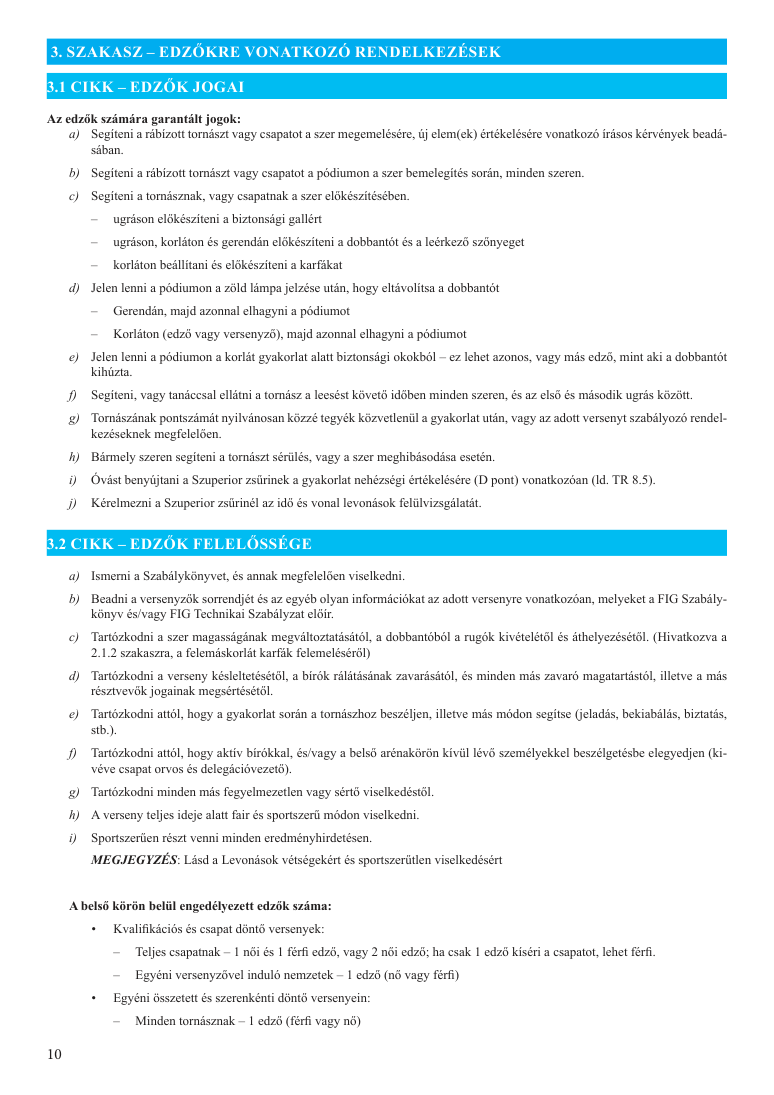


KINYERT SZÖVEG:

 3. SZAKASZ – EDZŐKRE VONATKOZÓ RENDELKEZÉSEK

3.1 CIKK – EDZŐK JOGAI

Az edzők számára garantált jogok:
    a)  Segíteni a rábízott tornászt vagy csapatot a szer megemelésére, új elem(ek) értékelésére vonatkozó írásos kérvények beadá­
        sában.
    b)  Segíteni a rábízott tornászt vagy csapatot a pódiumon a szer bemelegítés során, minden szeren.
    c)  Segíteni a tornásznak, vagy csapatnak a szer előkészítésében.
       –   ugráson előkészíteni a biztonsági gallért
       –   ugráson, korláton és gerendán előkészíteni a dobbantót és a leérkező szőnyeget
       –   korláton beállítani és előkészíteni a karfákat
    d)  Jelen lenni a pódiumon a zöld lámpa jelzése után, hogy eltávolítsa a dobbantót
       –   Gerendán, majd azonnal elhagyni a pódiumot
       –   Korláton (edző vagy versenyző), majd azonnal elhagyni a pódiumot
    e)  Jelen lenni a pódiumon a korlát gyakorlat alatt biztonsági okokból – ez lehet azonos, vagy más edző, mint aki a dobbantót
         k

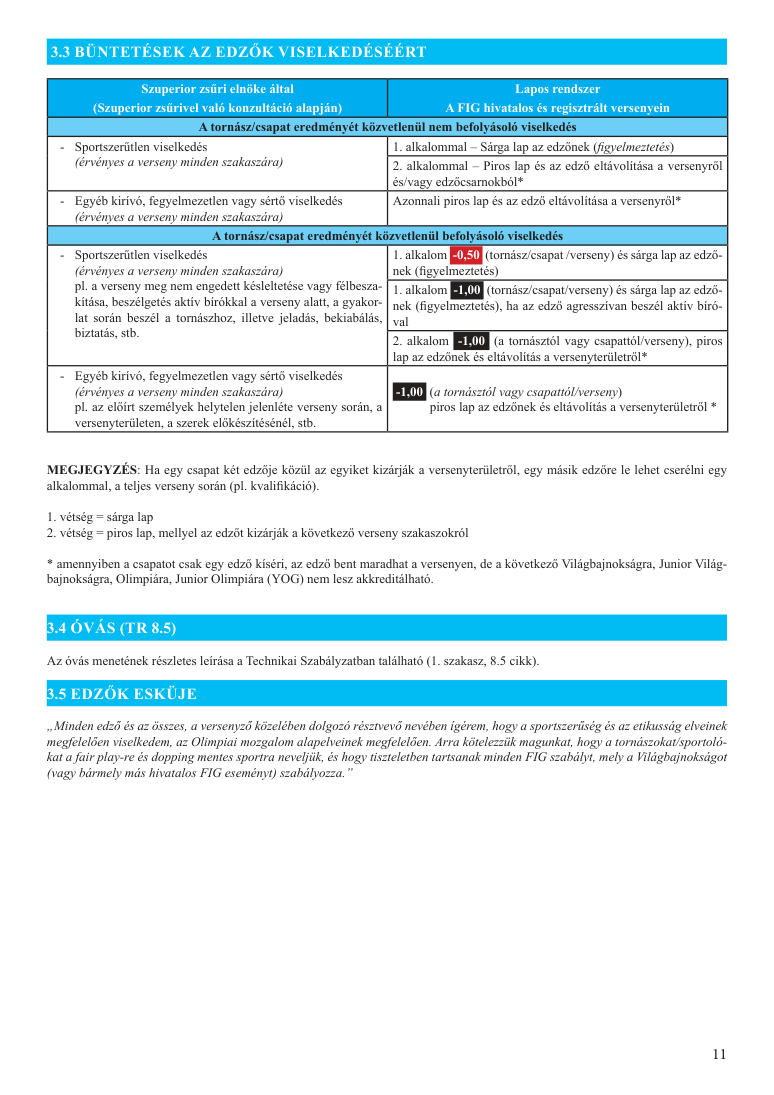


KINYERT SZÖVEG:

 3.3 BÜNTETÉSEK AZ EDZŐK VISELKEDÉSÉÉRT

               Szuperior zsűri elnöke által                                 Lapos rendszer
        (Szuperior zsűrivel való konzultáció alapján)           A FIG hivatalos és regisztrált versenyein
                A tornász/csapat eredményét közvetlenül nem befolyásoló viselkedés
   -  Sportszerűtlen viselkedés                                      1. alkalommal – Sárga lap az edzőnek (figyelmeztetés)
     (érvényes a verseny minden szakaszára)                      2. alkalommal – Piros lap és az edző eltávolítása a versenyről
                                                             és/vagy edzőcsarnokból*
   -  Egyéb kirívó, fegyelmezetlen vagy sértő viselkedés        Azonnali piros lap és az edző eltávolítása a versenyről*
     (érvényes a verseny minden szakaszára)
                  A tornász/csapat eredményét közvetlenül befolyásoló viselkedés
   -  Sportszerűtlen viselkedés                                      1. alkalom

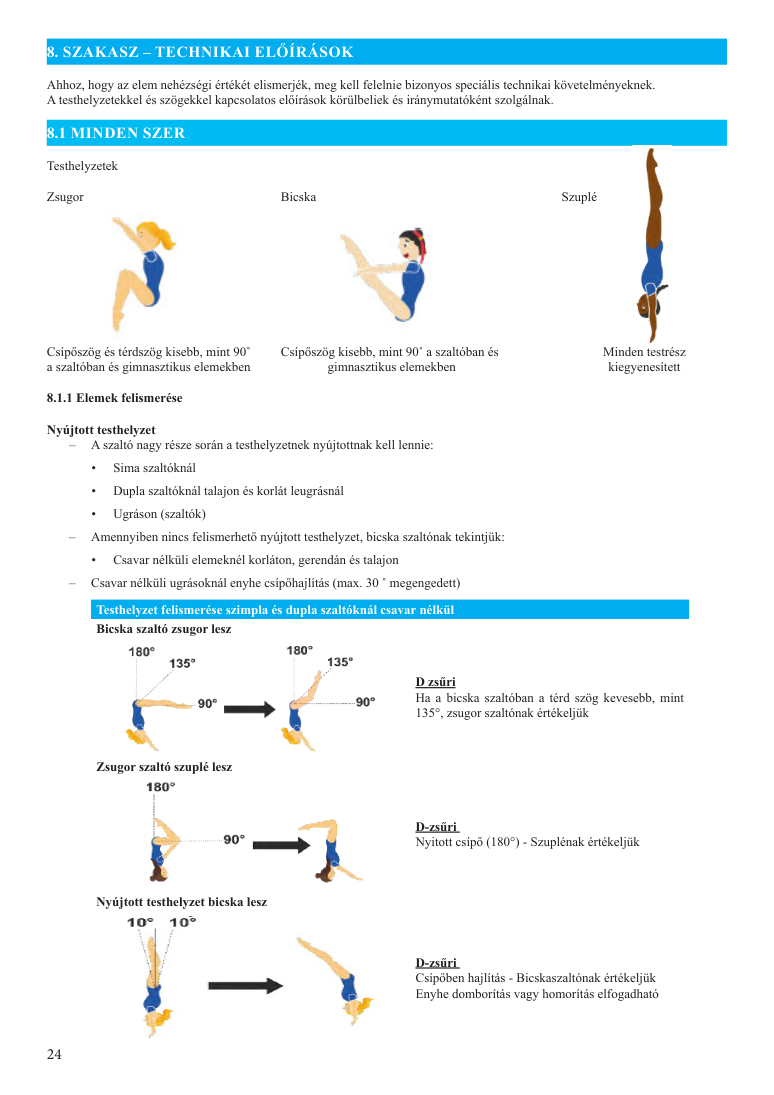


KINYERT SZÖVEG:

8. SZAKASZ – TECHNIKAI ELŐÍRÁSOK

Ahhoz, hogy az elem nehézségi értékét elismerjék, meg kell felelnie bizonyos speciális technikai követelményeknek.
A testhelyzetekkel és szögekkel kapcsolatos előírások körülbeliek és iránymutatóként szolgálnak.

8.1 MINDEN SZER

Testhelyzetek

Zsugor                                 Bicska                                          Szuplé





Csípőszög és térdszög kisebb, mint 90˚     Csípőszög kisebb, mint 90˚ a szaltóban és               Minden testrész
a szaltóban és gimnasztikus elemekben             gimnasztikus elemekben                              kiegyenesített

8.1.1 Elemek felismerése

Nyújtott testhelyzet
   –  A szaltó nagy része során a testhelyzetnek nyújtottnak kell lennie:
          •   Sima szaltóknál
          •   Dupla szaltóknál talajon és korlát leugrásnál
          •   Ugráson (szaltók)
   –  Amennyiben nincs felismerhető nyújtott testhelyzet, bicska szaltónak tekintjük:
          •   Csavar nélküli elemeknél kor

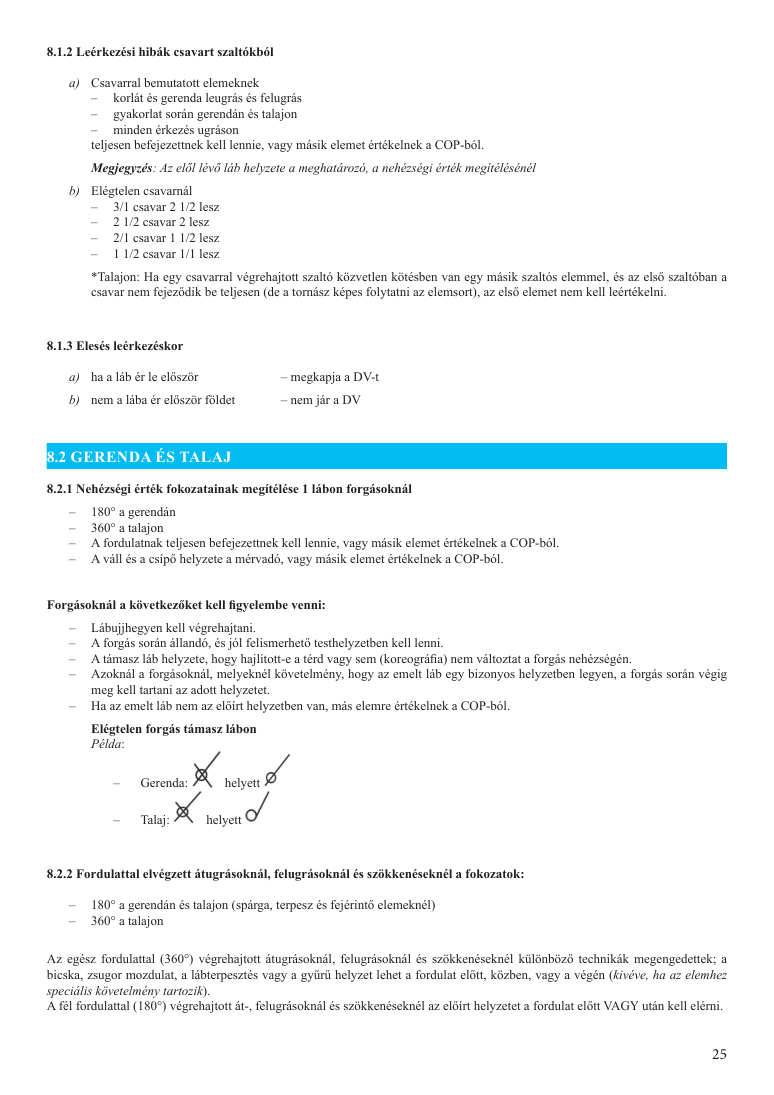


KINYERT SZÖVEG:

8.1.2 Leérkezési hibák csavart szaltókból

    a)  Csavarral bemutatott elemeknek
       –   korlát és gerenda leugrás és felugrás
       –   gyakorlat során gerendán és talajon
       –  minden érkezés ugráson
         teljesen befejezettnek kell lennie, vagy másik elemet értékelnek a COP-ból.
       Megjegyzés: Az elől lévő láb helyzete a meghatározó, a nehézségi érték megítélésénél
    b)  Elégtelen csavarnál
       –   3/1 csavar 2 1/2 lesz
       –  2 1/2 csavar 2 lesz
       –   2/1 csavar 1 1/2 lesz
       –  1 1/2 csavar 1/1 lesz
        *Talajon: Ha egy csavarral végrehajtott szaltó közvetlen kötésben van egy másik szaltós elemmel, és az első szaltóban a
        csavar nem fejeződik be teljesen (de a tornász képes folytatni az elemsort), az első elemet nem kell leértékelni.


8.1.3 Elesés leérkezéskor

    a)  ha a láb ér le először             – megkapja a DV-t
    b)  nem a lába ér először földet       – nem jár a DV


8.2 GERENDA ÉS TALAJ

8.2.1 Nehézségi 

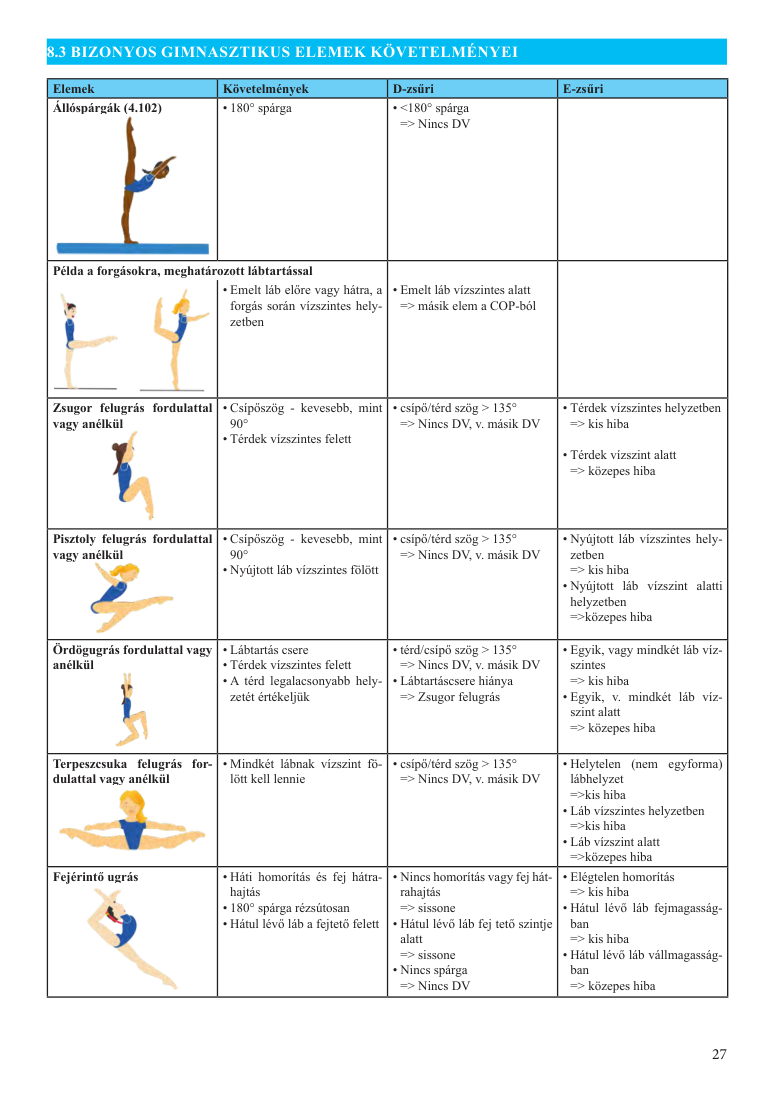


KINYERT SZÖVEG:

8.3 BIZONYOS GIMNASZTIKUS ELEMEK KÖVETELMÉNYEI

 Elemek                   Követelmények              D-zsűri                      E-zsűri
 Állóspárgák (4.102)             • 180° spárga                      • <180° spárga
                                                => Nincs DV





 Példa a forgásokra, meghatározott lábtartással
                                       • Emelt láb előre vagy hátra, a  • Emelt láb vízszintes alatt
                                  forgás során vízszintes hely­  => másik elem a COP-ból
                                zetben




 Zsugor felugrás fordulattal  • Csípőszög - kevesebb, mint  • csípő/térd szög > 135°          • Térdek vízszintes helyzetben
 vagy anélkül                  90°                     => Nincs DV, v. másik DV    => kis hiba
                                       • Térdek vízszintes felett
                                                                                                                 • Térdek vízszin

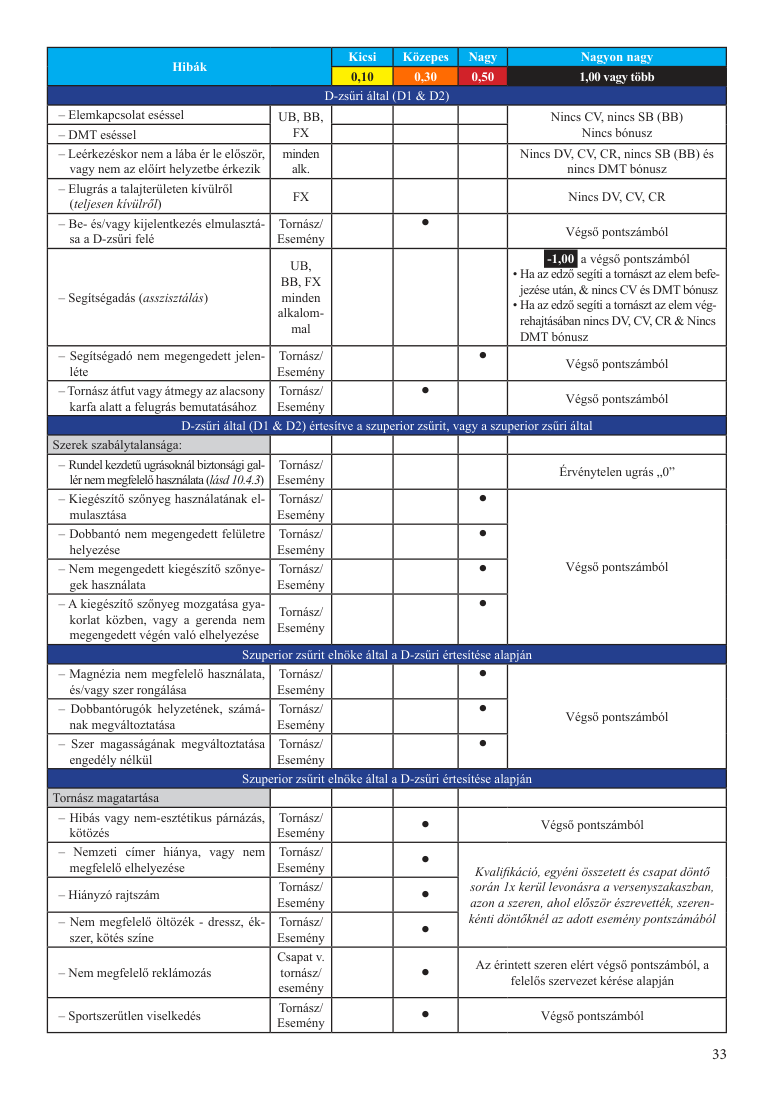


KINYERT SZÖVEG:

                                                    Kicsi    Közepes   Nagy            Nagyon nagy
                 Hibák
                                                    0,10       0,30      0,50                1,00 vagy több
                                                 D-zsűri által (D1 & D2)
 – Elemkapcsolat eséssel             UB, BB,                                     Nincs CV, nincs SB (BB)
 – DMT eséssel                   FX                                             Nincs bónusz
 – Leérkezéskor nem a lába ér le először,   minden                                 Nincs DV, CV, CR, nincs SB (BB) és
   vagy nem az előírt helyzetbe érkezik       alk.                                               nincs DMT bónusz
 – Elugrás a talajterületen kívülről                             FX                                           Nincs DV, CV, CR   (teljesen kívülről)
 – Be- és/vagy kijelentkezés elmulasztá­  Tornász/                                                  

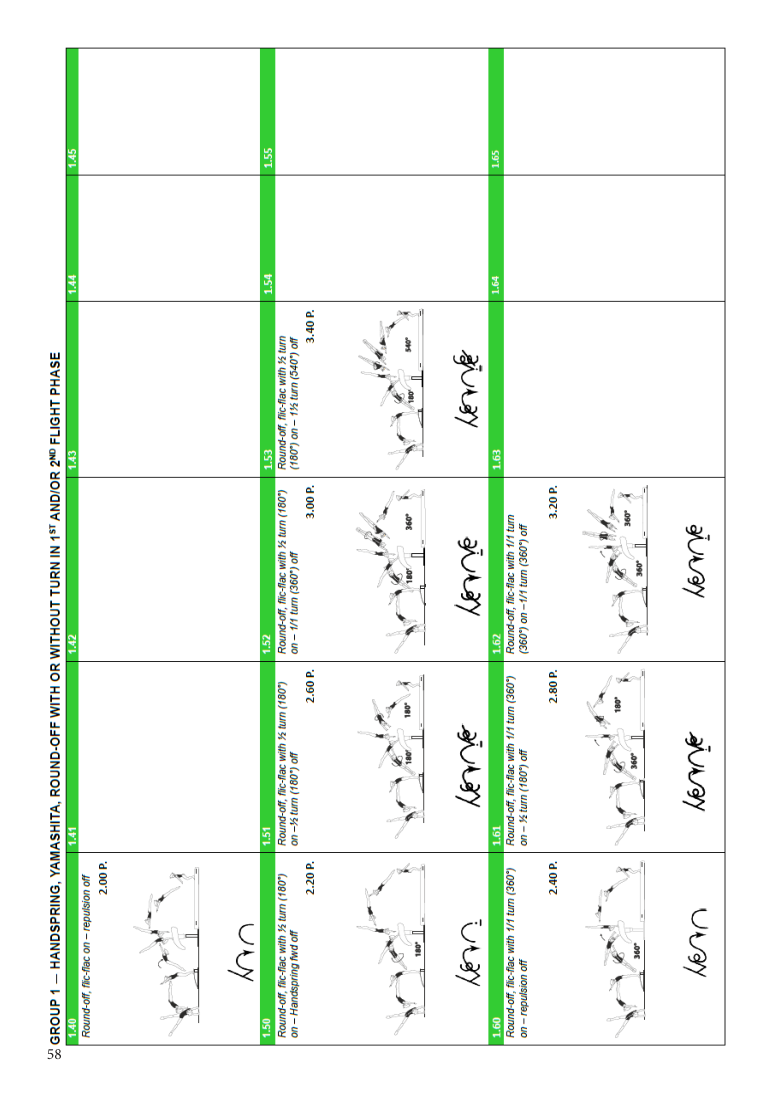


KINYERT SZÖVEG:

58


In [15]:

import matplotlib.pyplot as plt
import pymupdf

# Vizsgálandó oldalak
sample_pages = {
    10: "Csak szöveg",
    11: "Szöveg + táblázat",
    24: "Szöveg + kép",
    25: "Elemjelölő rajzok",
    27: "Táblázat + kép",
    33: "Teljes oldalas táblázat",
    58: "Képalapú elemtáblázat"
}

for page_num, content_type in sample_pages.items():

    # Eredeti PDF-oldal
    page = doc[page_num - 1]
    pix = page.get_pixmap(matrix=pymupdf.Matrix(1.3, 1.3))
    page_image = pix.samples

    # Kinyert szöveg
    extracted_text = pages[page_num - 1]["text"]

    print(f"\n{'=' * 70}")
    print(f"OLDAL: {page_num} | {content_type}")
    print(f"Kinyert karakterek: {len(extracted_text)}")
    print(f"{'=' * 70}")

    # PDF-oldal megjelenítése
    from IPython.display import display, Image

    display(
        Image(
            data=pix.tobytes("png"),
            width=650
        )
    )

    # Teljes kinyert szöveg
    print("\nKINYERT SZÖVEG:\n")
    print(extracted_text if extracted_text.strip() else "[NINCS KINYERHETŐ SZÖVEG]")


# KONKLÚZIÓ

A manuális ellenőrzés alapján a szövegkinyerés megfelelő, de bizonyos dokumentumrészek külön feldolgozást igényelnek:

- **32–34. oldal:** A táblázatok szerkezete nem maradt meg megfelelően, ezért tartalmukat manuálisan, soronként összefűzött szöveges formában (`.txt`) dolgozom fel.
- **57–165. oldal:** Képalapú elemtáblázatok, amelyeket kizárok az automatikus szövegkinyerésből. Helyettük strukturált táblázatot készítek belőlük az elemek nevével, kódszámával és D-értékével. - kb 100 db elemet teszek bele a demóhoz - minden szerről 25-öt kategóriánként kb ugyanolyan arányban
- **166–177. oldal:** Szimbólumtáblázatok és pontozói táblázatok, ezeket nem fogom felvenni a Pinecone adatbázisba, mert bírói szemmel nincs annyi hozzáadott értékük, képalapúak és a szimbólumok most nem scope.
- **184–210. oldal:** Elemszimbólumok és többnyelvű kifejezések, amelyek feldolgozása nem scope.



In [16]:

import pymupdf
import pandas as pd

# Kizárandó oldaltartományok (mindkét végponttal)
excluded_ranges = [
    (32, 34),
    (57, 177),
    (184, 210)
]

# Megtartandó oldalak meghatározása
excluded_pages = {
    page
    for start, end in excluded_ranges
    for page in range(start, end + 1)
}

kept_pages = [
    page
    for page in range(1, len(doc) + 1)
    if page not in excluded_pages
]

#új PDF létrehozása
output_path = PROJECT_ROOT / "data" / "processed" / "wag_cleaned.pdf"
output_path.parent.mkdir(parents=True, exist_ok=True)

cleaned_doc = pymupdf.open()

for page_num in kept_pages:
    cleaned_doc.insert_pdf(
        doc,
        from_page=page_num - 1,
        to_page=page_num - 1
    )

cleaned_doc.save(output_path)
cleaned_doc.close()

print(f"eredeti oldalszám: {len(doc)}")
print(f"kizárt oldalak: {len(excluded_pages)}")
print(f"megtartott oldalak: {len(kept_pages)}")
print(f"mentve: {output_path}")



#eredeti és új PDF oldalszámok összerendelése
df_page_mapping = pd.DataFrame({
    "cleaned_page": range(1, len(kept_pages) + 1),
    "original_page": kept_pages
})

mapping_path = (
    PROJECT_ROOT / "data" / "processed" / "page_mapping.csv"
)

df_page_mapping.to_csv(
    mapping_path,
    index=False,
    encoding="utf-8-sig"
)

display(df_page_mapping.head(10))
display(df_page_mapping.tail(10))



eredeti oldalszám: 210
kizárt oldalak: 151
megtartott oldalak: 59
mentve: C:\Users\aszen\Desktop\ÓBUDAI MSC\03_2026-2027-1\02_MI_alkalmazási területei\00_Beadando\gyamnastics_rag_assistant\data\processed\wag_cleaned.pdf


,cleaned_page,original_page
0,1,1
1,2,2
2,3,3
3,4,4
4,5,5
5,6,6
6,7,7
7,8,8
8,9,9
9,10,10


,cleaned_page,original_page
49,50,53
50,51,54
51,52,55
52,53,56
53,54,178
54,55,179
55,56,180
56,57,181
57,58,182
58,59,183
